In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_excel("student_performance.xlsx")
df


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D
...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,Male,2.8,75.4,8.2,Masters,Yes,Yes,No,60.5,70.7,C
996,997,Male,6.7,88.4,7.1,NaN,No,Yes,No,82.2,99.5,A
997,998,Female,2.6,84.5,8.0,High School,Yes,Yes,Yes,65.2,79.2,C
998,999,Female,4.6,85.3,8.1,High School,No,No,Yes,52.2,82.2,B


In [3]:
print("/n MISSING VALUES")
print(df.isnull().sum())
print("duplicate before removal:",df.duplicated().sum())

/n MISSING VALUES
student_id                      0
gender                          0
study_time_hours                0
attendance_percent              0
sleep_hours                     0
parental_education            102
internet_access                 0
extracurricular_activities      0
part_time_job                   0
previous_grade                  0
final_exam_score                0
final_grade                     0
dtype: int64
duplicate before removal: 0


In [4]:
df=df.drop_duplicates()
print("Duplicaes After Removal:",df.duplicated().sum())

Duplicaes After Removal: 0


gender
Female    510
Male      490
Name: count, dtype: int64


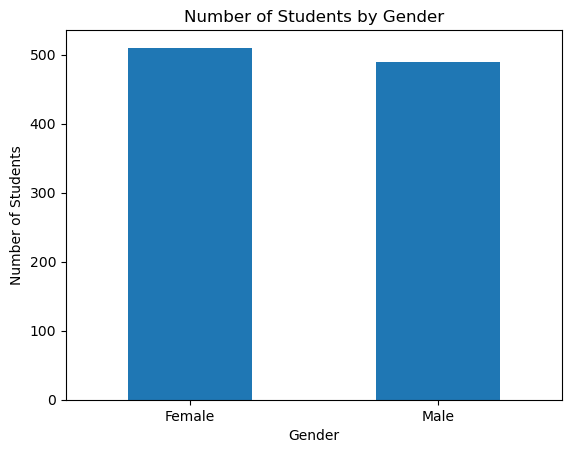

In [5]:
# 1. HOW MANY MALE AND FEMALE STUDENTS ARE THERE?

gender_counts = df["gender"].value_counts()

print(gender_counts)

gender_counts.plot(kind="bar")

plt.title("Number of Students by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

parental_education
High School    356
Bachelors      308
Masters        184
PhD             50
Name: count, dtype: int64


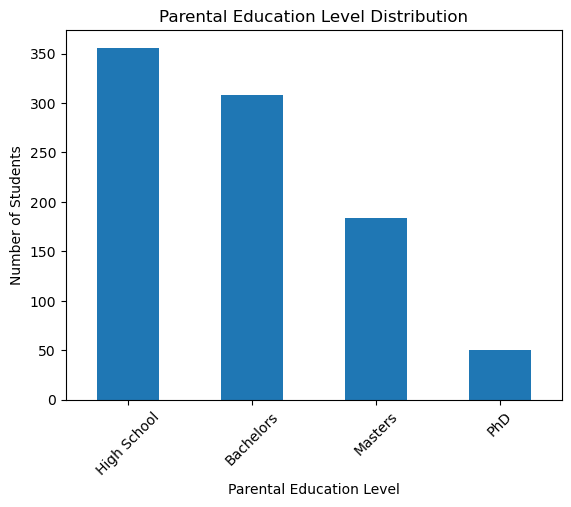

In [6]:
# 2. WHICH PARENTAL EDUCATION LEVEL IS MOST COMMON?

parental_count=df["parental_education"].value_counts()
print(parental_count)
parental_count.plot(kind="bar")
plt.title("Parental Education Level Distribution")
plt.xlabel("Parental Education Level")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.show()

final_grade
B    354
A    284
C    261
D     89
F     12
Name: count, dtype: int64


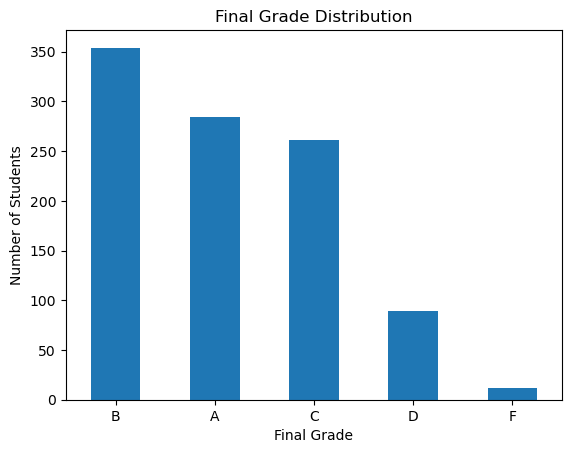

In [7]:
# 3. WHAT IS THE DISTRIBUTION OF FINAL GRADES?

grade_counts=df["final_grade"].value_counts()
print(grade_counts)
grade_counts.plot(kind="bar")
plt.title("Final Grade Distribution")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

gender
Female    83.606863
Male      83.477551
Name: final_exam_score, dtype: float64


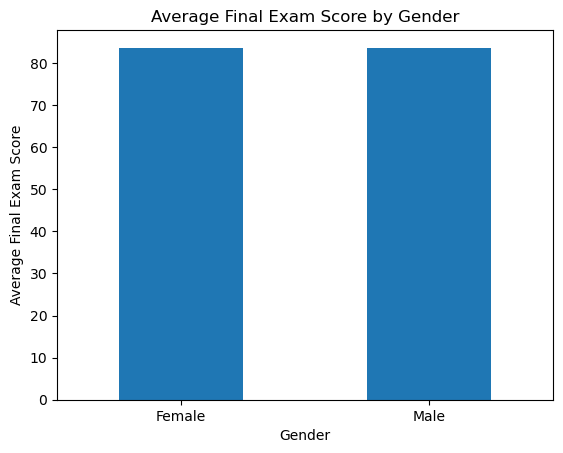

In [8]:
# 4. WHICH GENDER HAS THE HIGHEST AVERAGE FINAL EXAM SCORE?
avg_gender_score=(
    df.groupby("gender")["final_exam_score"]
    .mean()
)
print(avg_gender_score.sort_values(ascending=False))
avg_gender_score.plot(kind="bar")
plt.title("Average Final Exam Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Final Exam Score")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#5. DOES STUDY TIME AFFECT FINAL EXAM SCORE?

correlation=df["study_time_hours"].corr(
    df["final_exam_score"]
)
print("correlation:",correlation)
sns.scatterplot(
    data=df,
    x="study_time_hours",
    y="final_exam_score"
)
plt.title("Study Time vs Final Exam Score")
plt.xlabel("Study Time Hours")
plt.ylabel("Final Exam Score")
plt.show()

correlation: 0.2618717790919858


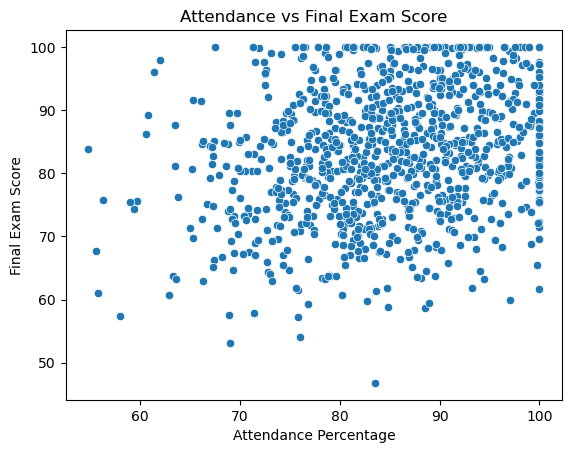

In [9]:
# 6. DOES ATTENDANCE AFFECT FINAL EXAM SCORE?


correlation=df["attendance_percent"].corr(
    df["final_exam_score"]
)
print("correlation:",correlation)
sns.scatterplot(
    data=df,
    x="attendance_percent",
    y="final_exam_score"
)
plt.title("Attendance vs Final Exam Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Exam Score")
plt.show()


Correlation: 0.40632715415561327


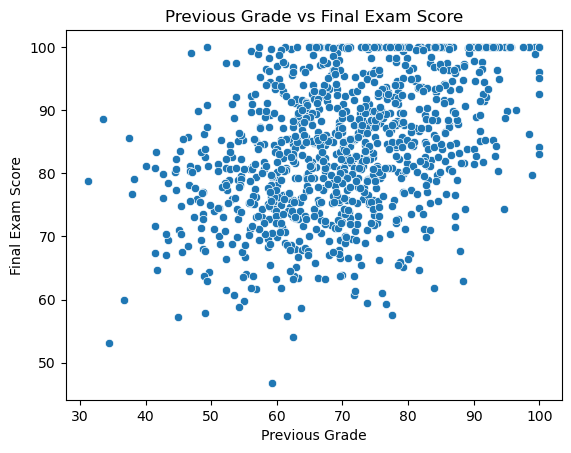

In [10]:
# 7. IS PREVIOUS GRADE RELATED TO FINAL EXAM SCORE?

correlation=df["previous_grade"].corr(
    df["final_exam_score"]
)
print("Correlation:", correlation)
sns.scatterplot(
    data=df,
    x="previous_grade",
    y="final_exam_score"
)
plt.title("Previous Grade vs Final Exam Score")
plt.xlabel("Previous Grade")
plt.ylabel("Final Exam Score")
plt.show()


correlation


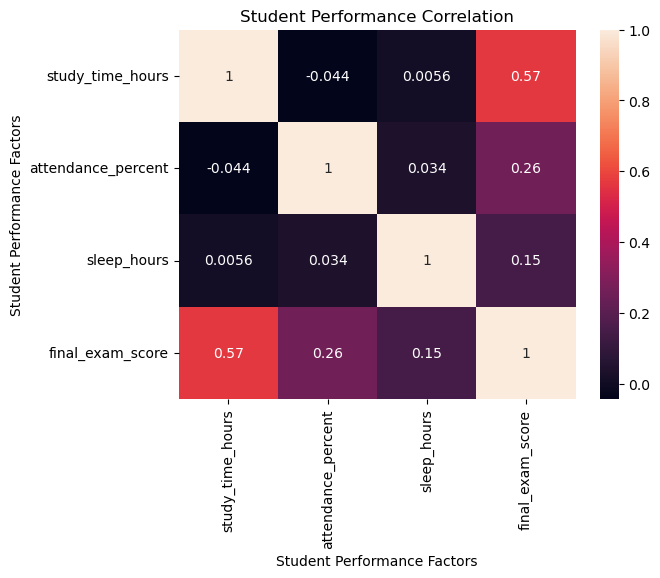

In [12]:
correlation=df[
    [
        "study_time_hours",
        "attendance_percent",
        "sleep_hours",
        "final_exam_score"
    ]
].corr()
print("correlation")
sns.heatmap(
    correlation,
    annot=True
)
plt.title("Student Performance Correlation")
plt.xlabel("Student Performance Factors")
plt.ylabel("Student Performance Factors")
plt.show()